<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta6_g%C3%B6rev2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Oylama matrisi 'hough_accumulator.png' olarak kaydedildi.


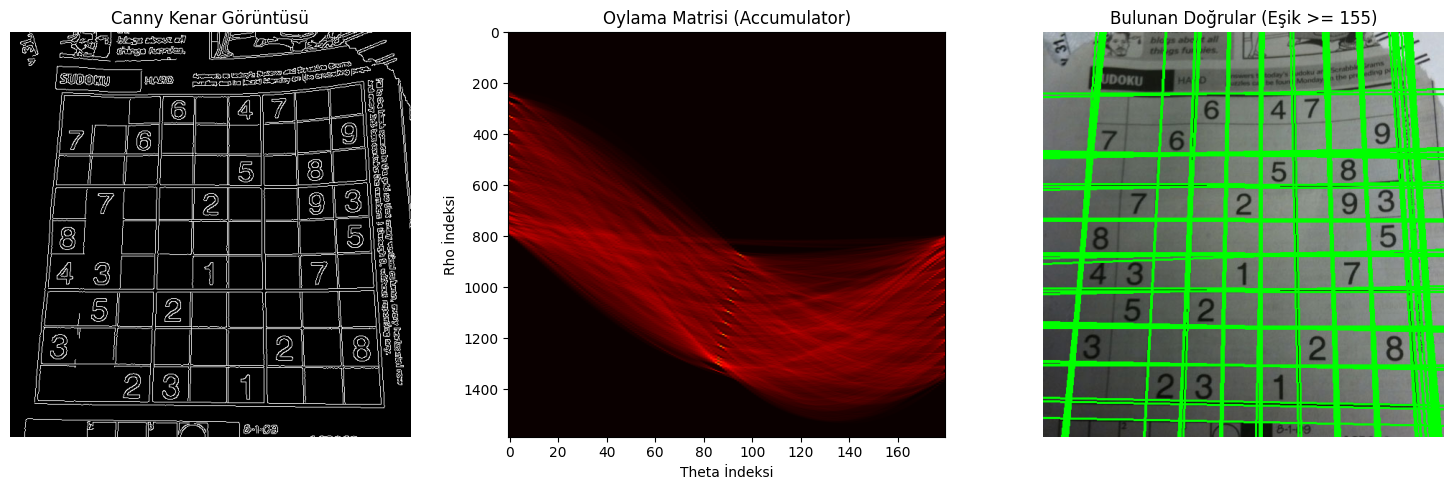

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# 1. Görüntüyü indir ve kenar görüntüsü elde et
url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)

# 2. Sin ve Cos değerlerini baştan hesaplayıp bellekte tutma
# Theta açıları: -90 dereceden +90 dereceye (radyan cinsinden)
thetas = np.deg2rad(np.arange(-90.0, 90.0, 1.0))
cos_vals = np.cos(thetas)
sin_vals = np.sin(thetas)
num_thetas = len(thetas)

# 3. Rho aralığı ve 2 boyutlu oylama matrisini (accumulator) oluşturma
height, width = edges.shape
diag_len = int(np.ceil(np.sqrt(height**2 + width**2)))  # Maksimum olası rho uzunluğu
rhos = np.arange(-diag_len, diag_len + 1, 1.0)
num_rhos = len(rhos)

# Oylama matrisi (satırlar: rho, sütunlar: theta)
accumulator = np.zeros((num_rhos, num_thetas), dtype=np.int32)

# 4. Oylama işlemi (Kenar pikselleri üzerinden geçerek oy verme)
edge_y, edge_x = np.nonzero(edges)  # Kenar olan piksellerin (y, x) koordinatları

for y, x in zip(edge_y, edge_x):
    for t_idx in range(num_thetas):
        rho = x * cos_vals[t_idx] + y * sin_vals[t_idx]
        # En yakın rho indeksini bul ve oylama matrisinde 1 artır
        rho_idx = int(np.argmin(np.abs(rhos - rho)))
        accumulator[rho_idx, t_idx] += 1

# 5. Oylama matrisini resim olarak kaydetme (0-255 aralığına normalize ederek)
acc_normalized = cv2.normalize(accumulator, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
cv2.imwrite('hough_accumulator.png', acc_normalized)
print("Oylama matrisi 'hough_accumulator.png' olarak kaydedildi.")

# 6. Eşik değere göre doğruları bulma ve orijinal resim üzerinde çizme
threshold = int(0.45 * accumulator.max())  # Eşik değer (en yüksek oyun %45'i)
detected_rho_idxs, detected_theta_idxs = np.where(accumulator >= threshold)

img_lines = img.copy()
for r_idx, t_idx in zip(detected_rho_idxs, detected_theta_idxs):
    rho = rhos[r_idx]
    theta = thetas[t_idx]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv2.line(img_lines, (x1, y1), (x2, y2), (0, 255, 0), 2)  # Yeşil çizgiler

# 7. Sonuçları görselleştirme
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(edges, cmap='gray')
plt.title('Canny Kenar Görüntüsü')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(acc_normalized, cmap='hot', aspect='auto')
plt.title('Oylama Matrisi (Accumulator)')
plt.xlabel('Theta İndeksi')
plt.ylabel('Rho İndeksi')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_lines, cv2.COLOR_BGR2RGB))
plt.title(f'Bulunan Doğrular (Eşik >= {threshold})')
plt.axis('off')

plt.tight_layout()
plt.show()